# Ablation Study — NASA Battery B0005 (v3)

**What v2 established.** The v2 harness is sound: delta-target A0 reaches 0.0077 SOH with
R2 = 0.989, against 0.4063 in v1. But the v2 ladder still could not be read, for two reasons
that only became visible once the per-seed numbers were printed.

**1. Seed noise swamps the component effects.** A5 is one architecture run five times with only
the seed changed:

| block | A5 per-seed RMSE | spread |
|---|---|---|
| level | 0.0661, 0.1341, 0.0272, 0.1956, 0.0913 | 7.2x |
| delta | 0.0086, 0.0173, 0.0421, 0.0071, 0.0190 | 5.9x |
| split-80 | 0.1106, 0.0116, 0.0173, 0.0265, 0.0953 | 9.5x |

The differences between configurations were 0.002-0.008. The spread *within* one configuration
was 0.099. Every single-seed row was one draw from a distribution far wider than the effect
being measured, so the ordering was noise. A4 and A5-seed-0 are the same config and the same
seed and still disagreed (0.0106 vs 0.1106), because the GPU LSTM kernels are non-deterministic.

**2. The protocol is too easy for architecture to matter.** Nothing beat persistence
(best 0.0077 vs persistence 0.0069). One-step-ahead prediction with the true previous cycle
always available is close to trivial -- which is both why persistence wins and why the
components are indistinguishable. Tian (SP = 80%) and Gao (start point 80) do **not** do this.
They forecast the remaining curve *recursively* from the start point, feeding predictions back
in. Persistence collapses there and architecture begins to earn its keep.

**What v3 changes**

| Problem | Fix |
|---|---|
| non-reproducible runs | `enable_op_determinism()` + per-run seeding |
| single-seed rows | **every row is `N_SEEDS` runs**, reported as mean +/- std |
| effects vs noise not separable | **paired per-seed deltas** and a `distinguishable?` verdict per row |
| task too easy | **Block 2: multi-step recursive forecasting** from the start point, as in Tian / Gao |
| no floor | persistence reported as a row in both blocks |

Block 1 is the one-step task (comparable with the paper). Block 2 is the recursive task
(comparable with the battery literature). Run from the folder containing `B0005.mat`.

In [1]:
import os, json, gc, time
os.environ['PYTHONHASHSEED'] = '42'
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
import numpy as np, pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, Dropout, Dense, LSTM,
                                     Bidirectional, Concatenate, Softmax, Multiply,
                                     Lambda, GlobalAveragePooling1D)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

try:
    tf.config.experimental.enable_op_determinism()
    print('op determinism enabled')
except Exception as e:
    print('op determinism unavailable (%s) -- results will still vary run to run' % e)
print('TF', tf.__version__, '| GPU', tf.config.list_physical_devices('GPU'))

op determinism enabled
TF 2.10.0 | GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
NAME, SLUG = 'NASA Battery B0005', 'battery_b0005'
MAT_PATH    = 'B0005.mat'
WINDOW      = 10
SPLIT_CYCLE = 50      # paper protocol
SPLIT_ALT   = 80      # matches Tian (SP=80%) and Gao (start point 80)
N_SEEDS     = 10      # every configuration is run this many times
EPOCHS, BATCH, PATIENCE = 300, 8, 30
UNITS, FILTERS, HEAD = 16, 16, 32
SEED = 42
BASELINE_RMSE = 0.0253      # 0.047 Ah on the SOH scale
np.random.seed(SEED); tf.random.set_seed(SEED)

In [3]:
from scipy.io import loadmat
mat = loadmat(MAT_PATH); cycles = mat['B0005'][0, 0]['cycle'][0]
rows, n = [], 0
for i in range(len(cycles)):
    r = cycles[i]
    if r['type'][0] != 'discharge':
        continue
    n += 1; d = r['data'][0][0]
    V = d['Voltage_measured'][0].astype(float); T = d['Temperature_measured'][0].astype(float)
    t = d['Time'][0].astype(float)
    tt = lambda vth: (float(t[np.where(V <= vth)[0][0]]) if len(np.where(V <= vth)[0]) else float(t[-1]))
    rows.append(dict(cycle=n, capacity=float(d['Capacity'][0][0]),
                     discharge_time=float(t[-1]), t_to_3p8V=tt(3.8), t_to_3p5V=tt(3.5),
                     mean_voltage=float(V.mean()), min_voltage=float(V.min()),
                     mean_temp=float(T.mean()), max_temp=float(T.max()),
                     temp_rise=float(T.max() - T[0])))
HI = pd.DataFrame(rows)
C0 = HI['capacity'].iloc[0]
HI['SOH'] = (HI['capacity'] / C0).astype(np.float32)
S_ALL = HI['SOH'].values.astype(np.float32)
CYC   = HI['cycle'].values
BASE_COLS = ['capacity']
FULL_COLS = [c for c in HI.columns if c not in ('cycle', 'SOH')]
print('cycles %d | initial capacity %.4f Ah' % (len(HI), C0))

cycles 168 | initial capacity 1.8565 Ah


In [4]:
def load(variant, split_cycle=SPLIT_CYCLE, target='level'):
    cols = BASE_COLS if variant == 'base' else FULL_COLS
    ref = HI[cols].iloc[0].replace(0, 1.0)              # fixed constant, nothing fitted
    Fm  = (HI[cols] / ref).values.astype(np.float32)
    Xa, ya, Xt, yt, prev = [], [], [], [], []
    for e in range(WINDOW, len(HI)):
        seq  = Fm[e - WINDOW:e]
        yval = S_ALL[e] if target == 'level' else S_ALL[e] - S_ALL[e - 1]
        if CYC[e] < split_cycle: Xa.append(seq); ya.append(yval)
        else: Xt.append(seq); yt.append(yval); prev.append(S_ALL[e - 1])
    f = lambda a: np.asarray(a, np.float32)
    Xa, ya, Xt, yt, prev = f(Xa), f(ya), f(Xt), f(yt), f(prev)
    cut = int(0.8 * len(Xa))
    return Xa[:cut], ya[:cut], Xa[cut:], ya[cut:], Xt, yt, prev

def persistence_rmse(split_cycle):
    idx = [e for e in range(WINDOW, len(HI)) if CYC[e] >= split_cycle]
    return float(np.sqrt(mean_squared_error(S_ALL[idx], S_ALL[[e - 1 for e in idx]])))

def persistence_rollout_rmse(split_cycle):
    """Flat-line forecast from the last observed cycle -- the honest floor for Block 2."""
    st = int(np.where(CYC >= split_cycle)[0][0])
    return float(np.sqrt(mean_squared_error(S_ALL[st:], np.full(len(HI) - st, S_ALL[st - 1]))))

for sc in (SPLIT_CYCLE, SPLIT_ALT):
    print('split %d | one-step persistence %.5f | recursive persistence %.5f'
          % (sc, persistence_rmse(sc), persistence_rollout_rmse(sc)))

split 50 | one-step persistence 0.00689 | recursive persistence 0.18103
split 80 | one-step persistence 0.00748 | recursive persistence 0.09910


In [5]:
def attention_pool(seq):
    score = Dense(1, activation='tanh')(seq)
    w = Softmax(axis=1)(score)
    return Lambda(lambda x: K.sum(x, axis=1))(Multiply()([seq, w]))

def build_model(shape, bidirectional=False, attention=False, multiscale=False,
                units=UNITS, filters=FILTERS, lr=1e-3, seed=SEED):
    ini = tf.keras.initializers.GlorotUniform(seed=seed)
    kw  = dict(kernel_initializer=ini)
    inp = Input(shape=shape); x = inp
    if multiscale:
        c = Concatenate()([Conv1D(filters, k, padding='same', activation='relu', **kw)(x)
                           for k in (3, 5, 7)])
    else:
        c = Conv1D(filters, 3, padding='same', activation='relu', **kw)(x)
    c = Dropout(0.1, seed=seed)(c)
    if int(shape[0]) > 3:
        c = MaxPooling1D(2, padding='same')(c)
    c = Conv1D(filters, 3, padding='same', activation='relu', **kw)(c)
    c = GlobalAveragePooling1D()(c)
    lstm = LSTM(units, return_sequences=attention, **kw)
    r = Bidirectional(lstm)(x) if bidirectional else lstm(x)
    if attention:
        r = attention_pool(r)
    h = Concatenate()([c, r])
    h = Dense(HEAD, activation='relu', **kw)(h); h = Dropout(0.1, seed=seed)(h)
    m = Model(inp, Dense(1, activation='linear', **kw)(h))
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])
    return m

## Block 1 — one-step-ahead (the paper's protocol)

Every configuration is run `N_SEEDS` times. `mean +/- std` is the result; the single best seed is
shown only to make the point that quoting it would be indefensible.

In [6]:
def fit_once(cfg, data, seed, target):
    Xtr, ytr, Xva, yva, Xte, yte, prev = data
    tf.keras.backend.clear_session()
    np.random.seed(seed); tf.random.set_seed(seed)
    m = build_model(Xtr.shape[1:], seed=seed, **cfg)
    m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH, verbose=0,
          shuffle=True,
          callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
                     ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-6)])
    p   = m.predict(Xte, batch_size=512, verbose=0).ravel()
    lvl = p if target == 'level' else prev + p
    y   = yte if target == 'level' else prev + yte
    return m, float(np.sqrt(mean_squared_error(y, lvl))), float(r2_score(y, lvl))

def run_block1(ladder, split_cycle=SPLIT_CYCLE, target='delta'):
    cache, rec = {}, []
    t0 = time.time()
    for rid, label, key, cfg in ladder:
        ck = (key, split_cycle, target)
        if ck not in cache: cache[ck] = load(key, split_cycle, target)
        rs = []
        for s in range(N_SEEDS):
            _, rmse, _ = fit_once(cfg, cache[ck], SEED + s, target)
            rs.append(rmse); gc.collect()
        rec.append(dict(id=rid, config=label, variant=key, per_seed=[round(v, 5) for v in rs],
                        mean=float(np.mean(rs)), std=float(np.std(rs, ddof=1)),
                        best=float(np.min(rs)), worst=float(np.max(rs))))
        print('%-3s %-26s mean %.4f +/- %.4f   [best %.4f worst %.4f]'
              % (rid, label, np.mean(rs), np.std(rs, ddof=1), np.min(rs), np.max(rs)))
    print('total %.0f s' % (time.time() - t0))
    return rec

LADDER1 = [
    ("A0", "Baseline (capacity only)", 'base', dict(bidirectional=False, attention=False, multiscale=False)),
    ("A1", "+ health indicators",      'full', dict(bidirectional=False, attention=False, multiscale=False)),
    ("A2", "+ bidirectional",          'full', dict(bidirectional=True,  attention=False, multiscale=False)),
    ("A3", "+ attention pooling",      'full', dict(bidirectional=True,  attention=True,  multiscale=False)),
    ("A4", "+ multi-scale CNN",        'full', dict(bidirectional=True,  attention=True,  multiscale=True)),
]
print('=== Block 1: one-step, delta target, split %d, %d seeds/config ===' % (SPLIT_CYCLE, N_SEEDS))
block1 = run_block1(LADDER1)

=== Block 1: one-step, delta target, split 50, 10 seeds/config ===
A0  Baseline (capacity only)   mean 0.0077 +/- 0.0009   [best 0.0069 worst 0.0093]
A1  + health indicators        mean 0.0318 +/- 0.0169   [best 0.0067 worst 0.0589]
A2  + bidirectional            mean 0.0268 +/- 0.0144   [best 0.0119 worst 0.0595]
A3  + attention pooling        mean 0.0190 +/- 0.0119   [best 0.0073 worst 0.0406]
A4  + multi-scale CNN          mean 0.0252 +/- 0.0121   [best 0.0110 worst 0.0479]
total 487 s


In [7]:
def verdict_table(rec, floor, floor_name, tag=''):
    t = pd.DataFrame(rec)[['id','config','variant','mean','std','best','worst']]
    t['mean_Ah'] = (t['mean'] * C0).round(4)
    prev_m = t['mean'].shift(); prev_s = t['std'].shift()
    t['delta_mean'] = (t['mean'] - prev_m).round(4)
    # a component counts only if the change exceeds the combined run-to-run scatter
    pooled = np.sqrt(t['std']**2 + prev_s**2)
    t['noise_band'] = pooled.round(4)
    t['distinguishable'] = np.where(t['delta_mean'].isna(), '-',
                           np.where(t['delta_mean'].abs() > pooled, 'yes', 'no -- within noise'))
    t['beats_floor'] = np.where(t['mean'] < floor, 'yes', 'no')
    pd.set_option('display.width', 220)
    print('%s %s' % (NAME, tag))
    print('%s floor %.5f SOH (%.4f Ah) | published baseline %.4f SOH\n'
          % (floor_name, floor, floor * C0, BASELINE_RMSE))
    print(t.to_string(index=False))
    nd = (t['distinguishable'] == 'no -- within noise').sum()
    print('\n%d of %d added components are within run-to-run noise.' % (nd, len(t) - 1))
    return t

tbl1 = verdict_table(block1, persistence_rmse(SPLIT_CYCLE), 'one-step persistence',
                     tag='- Block 1 (one-step, split %d)' % SPLIT_CYCLE)

NASA Battery B0005 - Block 1 (one-step, split 50)
one-step persistence floor 0.00689 SOH (0.0128 Ah) | published baseline 0.0253 SOH

id                   config variant     mean      std     best    worst  mean_Ah  delta_mean  noise_band    distinguishable beats_floor
A0 Baseline (capacity only)    base 0.007736 0.000936 0.006914 0.009256   0.0144         NaN         NaN                  -          no
A1      + health indicators    full 0.031770 0.016880 0.006677 0.058883   0.0590      0.0240      0.0169                yes          no
A2          + bidirectional    full 0.026801 0.014395 0.011928 0.059506   0.0498     -0.0050      0.0222 no -- within noise          no
A3      + attention pooling    full 0.019017 0.011850 0.007313 0.040647   0.0353     -0.0078      0.0186 no -- within noise          no
A4        + multi-scale CNN    full 0.025239 0.012138 0.011049 0.047881   0.0469      0.0062      0.0170 no -- within noise          no

3 of 4 added components are within run-to-run noi

## Block 2 — recursive forecasting from the start point

This is what the battery literature actually does. The model is trained one-step-ahead on the
training cycles, then rolled forward from the start point using **its own predictions** as input,
with no further ground truth. Capacity-only, because the other indicators cannot be fed back
without leaking the test cycles.

Persistence here is a flat line from the last observed cycle, which is a genuinely weak
forecast — so this block can actually separate the architectures.

In [8]:
def rollout(m, split_cycle, target):
    st  = int(np.where(CYC >= split_cycle)[0][0])
    win = list(S_ALL[st - WINDOW:st].astype(np.float32))
    out = []
    for _ in range(st, len(HI)):
        x = np.asarray(win[-WINDOW:], np.float32).reshape(1, WINDOW, 1)
        p = float(m(x, training=False).numpy().ravel()[0])
        lvl = p if target == 'level' else win[-1] + p
        lvl = float(np.clip(lvl, 0.0, 1.2))
        out.append(lvl); win.append(lvl)
    y = S_ALL[st:]
    out = np.asarray(out, np.float32)
    return float(np.sqrt(mean_squared_error(y, out))), out, y

def run_block2(ladder, split_cycle, target='delta'):
    data = load('base', split_cycle, target)
    rec, curves = [], {}
    t0 = time.time()
    for rid, label, cfg in ladder:
        rs, last = [], None
        for s in range(N_SEEDS):
            m, _, _ = fit_once(cfg, data, SEED + s, target)
            r, curve, y = rollout(m, split_cycle, target)
            rs.append(r); last = curve; gc.collect()
        curves[rid] = last
        rec.append(dict(id=rid, config=label, variant='base', per_seed=[round(v, 5) for v in rs],
                        mean=float(np.mean(rs)), std=float(np.std(rs, ddof=1)),
                        best=float(np.min(rs)), worst=float(np.max(rs))))
        print('%-3s %-26s mean %.4f +/- %.4f   [best %.4f worst %.4f]'
              % (rid, label, np.mean(rs), np.std(rs, ddof=1), np.min(rs), np.max(rs)))
    print('total %.0f s' % (time.time() - t0))
    return rec, curves

LADDER2 = [
    ("B0", "Baseline",           dict(bidirectional=False, attention=False, multiscale=False)),
    ("B1", "+ bidirectional",    dict(bidirectional=True,  attention=False, multiscale=False)),
    ("B2", "+ attention pooling",dict(bidirectional=True,  attention=True,  multiscale=False)),
    ("B3", "+ multi-scale CNN",  dict(bidirectional=True,  attention=True,  multiscale=True)),
]
print('=== Block 2: recursive forecast from cycle %d, %d seeds/config ===' % (SPLIT_ALT, N_SEEDS))
block2, curves = run_block2(LADDER2, SPLIT_ALT)
tbl2 = verdict_table(block2, persistence_rollout_rmse(SPLIT_ALT), 'recursive persistence',
                     tag='- Block 2 (recursive, start cycle %d)' % SPLIT_ALT)

=== Block 2: recursive forecast from cycle 80, 10 seeds/config ===
B0  Baseline                   mean 0.0968 +/- 0.1555   [best 0.0121 worst 0.5096]
B1  + bidirectional            mean 0.0785 +/- 0.1225   [best 0.0090 worst 0.4125]
B2  + attention pooling        mean 0.0755 +/- 0.1199   [best 0.0092 worst 0.4082]
B3  + multi-scale CNN          mean 0.1249 +/- 0.0696   [best 0.0391 worst 0.2568]
total 529 s
NASA Battery B0005 - Block 2 (recursive, start cycle 80)
recursive persistence floor 0.09910 SOH (0.1840 Ah) | published baseline 0.0253 SOH

id              config variant     mean      std     best    worst  mean_Ah  delta_mean  noise_band    distinguishable beats_floor
B0            Baseline    base 0.096848 0.155475 0.012077 0.509627   0.1798         NaN         NaN                  -         yes
B1     + bidirectional    base 0.078466 0.122455 0.008957 0.412498   0.1457     -0.0184      0.1979 no -- within noise         yes
B2 + attention pooling    base 0.075519 0.119857 0.009

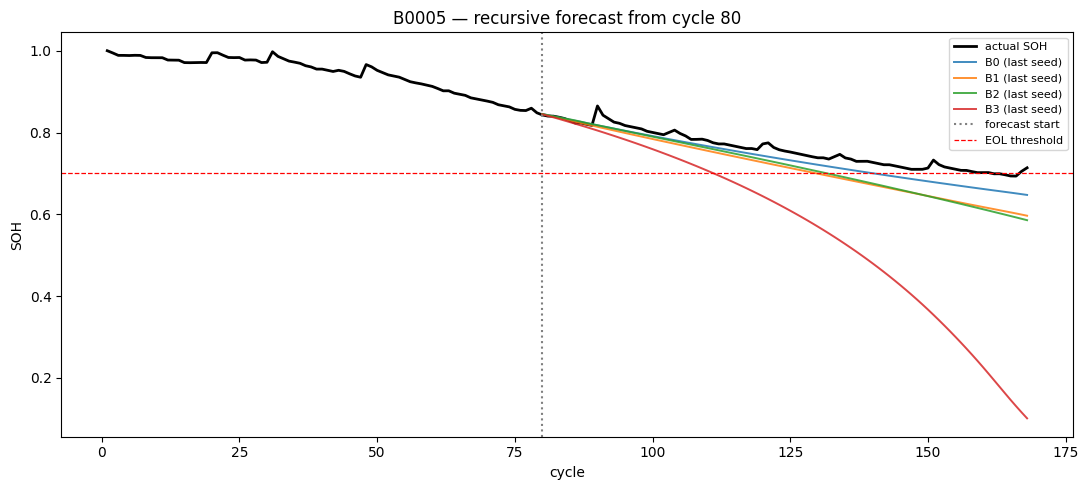

In [9]:
import matplotlib.pyplot as plt
st = int(np.where(CYC >= SPLIT_ALT)[0][0])
plt.figure(figsize=(11, 5))
plt.plot(CYC, S_ALL, 'k-', lw=2, label='actual SOH')
for rid, c in curves.items():
    plt.plot(CYC[st:], c, lw=1.4, alpha=.85, label='%s (last seed)' % rid)
plt.axvline(SPLIT_ALT, color='grey', ls=':', label='forecast start')
plt.axhline(0.70, color='r', ls='--', lw=.9, label='EOL threshold')
plt.xlabel('cycle'); plt.ylabel('SOH'); plt.legend(fontsize=8)
plt.title('B0005 — recursive forecast from cycle %d' % SPLIT_ALT); plt.tight_layout(); plt.show()

In [10]:
out = {'dataset': NAME, 'C0_Ah': float(C0), 'window': WINDOW, 'n_seeds': N_SEEDS,
       'published_baseline_rmse': BASELINE_RMSE,
       'floors': {'one_step_persistence_split%d' % SPLIT_CYCLE: persistence_rmse(SPLIT_CYCLE),
                  'recursive_persistence_split%d' % SPLIT_ALT: persistence_rollout_rmse(SPLIT_ALT)},
       'block1_one_step': block1, 'block2_recursive': block2}
json.dump(out, open('ablation_%s_results_v3.json' % SLUG, 'w'), indent=2)
tbl1.to_csv('ablation_%s_v3_block1.csv' % SLUG, index=False)
tbl2.to_csv('ablation_%s_v3_block2.csv' % SLUG, index=False)
print('saved v3 results + 2 tables')

saved v3 results + 2 tables
